# Clasificación de productos en categoría y subcategoría

**Objetivo.** Dado el nombre de un producto nuevo (por ejemplo,
`"Bebida de avena sin azúcar 1 L"`), predecir automáticamente:

1. su **categoría** (24 clases posibles), y
2. su **subcategoría** (134 clases posibles).

**Datos.** Usamos el catálogo de Mercadona de Madrid centro generado en el
Proyecto 1 (`Proyecto-1/Data/productos_madrid_centro.csv`). Cada fila es un
producto en un código postal, así que el mismo producto aparece repetido;
antes de entrenar nos quedamos con un producto por nombre.

**Enfoque.** Dos clasificadores de `scikit-learn` con la misma representación
de texto: TF-IDF de palabras y de caracteres + regresión logística. Se entrenan
por separado porque la categoría y la subcategoría tienen distinto nivel de
detalle, aunque comparten la misma entrada.

**Métricas.** Usamos *exactitud* (accuracy) y *F1 macro*. La segunda media da
el mismo peso a todas las clases, lo que importa porque algunas subcategorías
tienen muy pocos productos.


## 1. Entorno y datos


In [1]:
%matplotlib inline

import time

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from proyecto_2.classifier import (
    CATEGORY_COLUMN,
    DEFAULT_DATA_PATH,
    NAME_COLUMN,
    SUBCATEGORY_COLUMN,
    ProductClassifier,
    build_pipeline,
    fit_classifier,
    load_products,
    prepare_dataset,
    split_dataset,
)
from proyecto_2.mock_products import MOCK_PRODUCTS

pd.set_option("display.max_colwidth", 80)
print(f"Catálogo: {DEFAULT_DATA_PATH}")


Catálogo: /Users/santiago/Desktop/DSIA/groceries/Proyecto-1/Data/productos_madrid_centro.csv


El módulo `proyecto_2.classifier` contiene la lógica reutilizable. El notebook
la importa para poder explicar cada paso; el script de consola
(`scripts/classify_products.py`) usa exactamente las mismas funciones.


## 2. Exploración del catálogo


In [2]:
raw = load_products()
print(f"Filas: {len(raw):,}")
print(f"Nombres únicos: {raw[NAME_COLUMN].nunique():,}")
print(f"Categorías: {raw[CATEGORY_COLUMN].nunique()}")
print(f"Subcategorías: {raw[SUBCATEGORY_COLUMN].nunique()}")
raw.head(10)


Filas: 36,766
Nombres únicos: 3,571
Categorías: 24
Subcategorías: 135


,nombre,categoria,subcategoria
0,"Aceite de oliva 0,4º Hacendado","Aceite, especias y salsas","Aceite, vinagre y sal"
1,"Aceite de oliva 0,4º Hacendado","Aceite, especias y salsas","Aceite, vinagre y sal"
2,Aceite de oliva virgen extra Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"
3,Aceite de oliva virgen extra Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"
4,Aceite de oliva virgen extra Hacendado Gran Selección,"Aceite, especias y salsas","Aceite, vinagre y sal"
5,Aceite de oliva 1º Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"
6,Aceite de oliva 1º Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"
7,Aceite de oliva virgen Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"
8,Aceite de oliva virgen Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"
9,Aceite de oliva virgen extra Hacendado,"Aceite, especias y salsas","Aceite, vinagre y sal"


Hay muchas más filas que nombres únicos porque el scraping se hizo por código
postal. Entrenar con las filas repetidas daría más peso a los productos de los
CP con más datos y filtraría información del conjunto de prueba (el mismo
producto podría estar en train y en test). Por eso deduplicamos por nombre.


## 3. Limpieza y deduplicación


In [3]:
products = prepare_dataset(raw)
print(f"Productos únicos: {len(products):,}")
print(f"Filas eliminadas: {len(raw) - len(products):,}")
products.sample(10, random_state=42)


Productos únicos: 3,571
Filas eliminadas: 33,195


,nombre,categoria,subcategoria
457,Bronceador facial fluido Bronzer luminoso Deliplus 01 terracota,Maquillaje,Bases de maquillaje y corrector
1647,Helado bombón almendrado Hacendado sabor vainilla,Congelados,Helados
351,Bebida energética Monster Energy Ultra zero azúcar,Agua y refrescos,Isotónico y energético
1667,Helado peanut butter cups Hacendado mantequilla de cacahuete con trocitos de...,Congelados,Helados
1849,Lavavajillas a mano Bosque Verde,Limpieza y hogar,Limpieza vajilla
2111,Mascarilla cabello negro Color Mask Deliplus,Cuidado del cabello,Coloración cabello
1366,Exfoliante corporal marino Deliplus Sal Mar Muerto,Cuidado facial y corporal,Cuidado corporal
70,Activador Quitamanchas ropa de color Oxi Active Bosque Verde en gel,Limpieza y hogar,Detergente y suavizante ropa
1206,Difusor multifragancia eléctrico Bosque Verde con regulador de intensidad,Limpieza y hogar,Insecticida y ambientador
1213,Dorada abierta a la espalda,Marisco y pescado,Pescado fresco


`prepare_dataset` también resuelve un problema habitual: un mismo nombre puede
aparecer con etiquetas distintas (por ejemplo, un tomate frito clasificado a
veces como salsa y a veces como conserva). En esos casos se conserva la
combinación (categoría, subcategoría) más frecuente.


In [4]:
labels_per_name = raw.groupby(NAME_COLUMN)[
    [CATEGORY_COLUMN, SUBCATEGORY_COLUMN]
].nunique()
ambiguous = labels_per_name[
    (labels_per_name[CATEGORY_COLUMN] > 1)
    | (labels_per_name[SUBCATEGORY_COLUMN] > 1)
]
print(f"Nombres con más de una etiqueta: {len(ambiguous):,}")
ambiguous.head(10)


Nombres con más de una etiqueta: 198


,categoria,subcategoria
nombre,,
70% Alcohol limpieza hogar Bosque Verde perfumado con pistola,1,2
Aceite de Ricino Deliplus nutre y fortalece contiene aplicador,2,2
Agua de coco 100% Hacendado,1,2
Alas de pollo adobadas,1,2
Anillas de pota Argentina Hacendado congeladas,2,2
Anillas de pota a la romana Hacendado ultracongeladas,2,2
Aritos de surimi a la romana Hacendado ultracongelados,2,2
Arroz cocido basmati Sabroz Brillante,2,2
Arroz cocido integral Sabroz Brillante,2,2


## 4. Distribución de clases


In [5]:
category_counts = products[CATEGORY_COLUMN].value_counts()
subcategory_counts = products[SUBCATEGORY_COLUMN].value_counts()

print(f"Productos por categoría — mínimo: {category_counts.min()}, "
      f"máximo: {category_counts.max()}")
print(f"Productos por subcategoría — mínimo: {subcategory_counts.min()}, "
      f"mediana: {subcategory_counts.median():.0f}, "
      f"máximo: {subcategory_counts.max()}")
category_counts.to_frame("productos")


Productos por categoría — mínimo: 34, máximo: 411
Productos por subcategoría — mínimo: 2, mediana: 24, máximo: 90


,productos
categoria,
Cuidado facial y corporal,411
Limpieza y hogar,335
Panadería y pastelería,287
Charcutería y quesos,273
Carne,177
Cuidado del cabello,175
Congelados,157
Bodega,157
Fruta y verdura,148


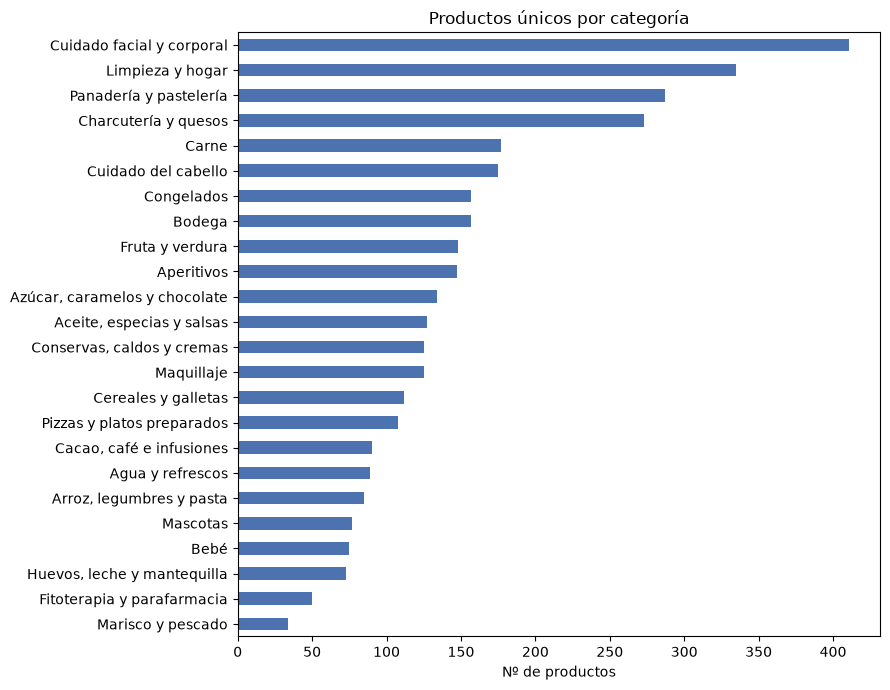

In [6]:
ax = category_counts.sort_values().plot.barh(figsize=(9, 7), color="#4C72B0")
ax.set_title("Productos únicos por categoría")
ax.set_xlabel("Nº de productos")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


Hay desbalance: categorías como *Cuidado facial y corporal* tienen miles de
productos, mientras que otras tienen unos cientos. Además, algunas
subcategorías tienen muy pocos ejemplos. Por eso usamos
`class_weight="balanced"` en la regresión logística y reportamos F1 macro.


## 5. Separación entrenamiento / prueba


In [7]:
train_df, test_df = split_dataset(products, test_size=0.2, random_state=42)

print(f"Entrenamiento: {len(train_df):,} ({len(train_df) / len(products):.0%})")
print(f"Prueba:        {len(test_df):,} ({len(test_df) / len(products):.0%})")
print(
    "Subcategorías representadas en test: "
    f"{test_df[SUBCATEGORY_COLUMN].nunique()} / "
    f"{products[SUBCATEGORY_COLUMN].nunique()}"
)


Entrenamiento: 2,856 (80%)
Prueba:        715 (20%)
Subcategorías representadas en test: 129 / 134


El split es **estratificado por subcategoría**: mantiene la proporción de cada
clase en train y test. Así todas las subcategorías, incluso las raras, tienen
al menos un ejemplo en evaluación. `random_state=42` hace el resultado
reproducible.


## 6. Representación del texto y modelo


### TF-IDF

`TfidfVectorizer` convierte cada nombre en un vector numérico. TF-IDF combina:

- **TF** (*term frequency*): cuánto aparece un término en el nombre.
- **IDF** (*inverse document frequency*): cuánto lo distingue del resto. Una
  palabra presente en todos los productos ("Hacendado") pesa poco; una
  específica ("pintalabios") pesa mucho.

Usamos dos vistas complementarias:

- **palabras** con n-gramas de 1 a 2: captura términos y expresiones como
  `"aceite de oliva"` o `"leche entera"`.
- **caracteres** con n-gramas de 3 a 5: captura fragmentos de palabras, marcas y
  variaciones ortográficas (`"pintalabios"`, `"pinta..."`).

### Regresión logística

Es un modelo lineal que aprende un peso por término y clase, y convierte las
puntuaciones en probabilidades con *softmax*. Es rápido, funciona bien con
texto TF-IDF y sus coeficientes son interpretables. `C=10` controla la
regularización: cuanto mayor es `C`, menos se penalizan los pesos grandes.
`class_weight="balanced"` compensa las clases con menos ejemplos.


In [8]:
build_pipeline()


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('palabras', ...), ('caracteres', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",'unicode'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that 

## 7. Entrenamiento


In [9]:
start = time.perf_counter()
classifier = fit_classifier(train_df, test_df, C=10.0)
elapsed = time.perf_counter() - start

print(f"Entrenamiento: {elapsed:.1f} s")
print()
for key, value in classifier.metrics.items():
    print(f"{key:34s} {value}")


Entrenamiento: 7.1 s

productos                          2856
num_categorias                     24
num_subcategorias                  134
accuracy_categoria_train           1.0
accuracy_subcategoria_train        1.0
prueba                             715
accuracy_categoria_test            0.9245
macro_f1_categoria_test            0.913
accuracy_subcategoria_test         0.8587
macro_f1_subcategoria_test         0.8299


La exactitud de entrenamiento es del 100 %: con TF-IDF de alta dimensión y 134
clases, el modelo puede memorizar los nombres. Lo relevante es el rendimiento
en el conjunto de prueba, que no se ha usado para ajustar los pesos.

Se entrenan dos pipelines independientes, uno para categoría y otro para
subcategoría. El conjunto de prueba no se toca durante el entrenamiento: se
usa solo en el siguiente paso.


## 8. Evaluación en el conjunto de prueba


In [10]:
test_predictions = classifier.test_predictions

print("=== CATEGORÍA ===")
print(
    classification_report(
        test_predictions["categoria_real"],
        test_predictions["categoria_predicha"],
        zero_division=0,
    )
)


=== CATEGORÍA ===
                               precision    recall  f1-score   support

    Aceite, especias y salsas       0.81      0.88      0.85        25
             Agua y refrescos       1.00      0.94      0.97        18
                   Aperitivos       0.83      0.86      0.85        29
     Arroz, legumbres y pasta       0.89      0.94      0.91        17
Azúcar, caramelos y chocolate       1.00      0.85      0.92        27
                         Bebé       1.00      0.93      0.97        15
                       Bodega       0.97      0.91      0.94        33
     Cacao, café e infusiones       0.94      0.94      0.94        18
                        Carne       0.94      0.86      0.90        36
          Cereales y galletas       0.87      0.87      0.87        23
         Charcutería y quesos       0.93      0.96      0.95        54
                   Congelados       0.91      0.91      0.91        32
   Conservas, caldos y cremas       0.85      0.88      0.

In [11]:
print("=== SUBCATEGORÍA: resumen ===")
print(
    f"Exactitud: {classifier.metrics['accuracy_subcategoria_test']:.1%} | "
    f"F1 macro: {classifier.metrics['macro_f1_subcategoria_test']:.1%}"
)

report = classification_report(
    test_predictions["subcategoria_real"],
    test_predictions["subcategoria_predicha"],
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
report_df = report_df.drop(
    index=["accuracy", "macro avg", "weighted avg"], errors="ignore"
)
print("Subcategorías con peor F1 (suelen ser las de menos ejemplos):")
report_df.sort_values("f1-score").head(12)[
    ["precision", "recall", "f1-score", "support"]
]


=== SUBCATEGORÍA: resumen ===
Exactitud: 85.9% | F1 macro: 83.0%
Subcategorías con peor F1 (suelen ser las de menos ejemplos):


,precision,recall,f1-score,support
Tónica y bitter,0.00,0.000000,0.000000,1.0
Limpiacristales,0.00,0.000000,0.000000,1.0
Biberón y chupete,0.00,0.000000,0.000000,1.0
Limpieza muebles y multiusos,0.00,0.000000,0.000000,3.0
Arreglos,0.00,0.000000,0.000000,3.0
Empanados y elaborados,0.00,0.000000,0.000000,3.0
Carne congelada,1.00,0.333333,0.500000,3.0
Bollería de horno,0.75,0.428571,0.545455,7.0
Gazpacho y cremas,0.50,0.666667,0.571429,3.0
Arroz y pasta,0.50,0.666667,0.571429,3.0


En la matriz de confusión, la diagonal son los aciertos. Los valores fuera de
la diagonal muestran confusiones entre categorías parecidas. Es normal que
algunas se confundan: el modelo solo ve el nombre, no la ubicación en la
tienda ni el formato.


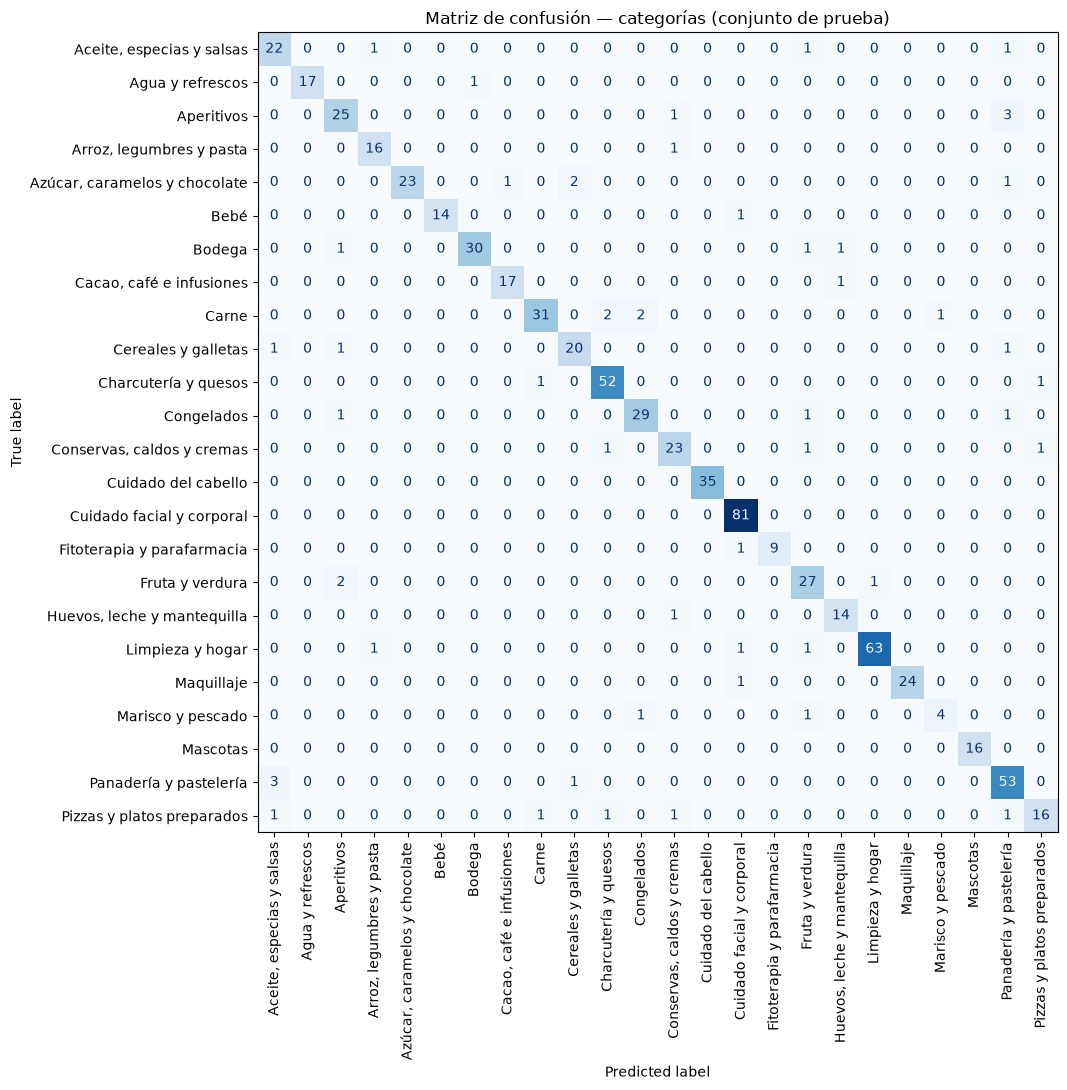

In [12]:
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay.from_predictions(
    test_predictions["categoria_real"],
    test_predictions["categoria_predicha"],
    ax=ax,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=90,
    values_format="d",
)
ax.set_title("Matriz de confusión — categorías (conjunto de prueba)")
plt.tight_layout()
plt.show()


## 9. ¿Qué ha aprendido el modelo?


Como la regresión logística es lineal, podemos inspeccionar los términos con
más peso en cada categoría. Los n-gramas de caracteres no se muestran para
mantener la tabla legible.


In [13]:
feature_names = classifier.category_model.named_steps["features"].get_feature_names_out()
coefficients = classifier.category_model.named_steps["modelo"].coef_
classes = classifier.category_model.classes_
word_positions = [
    i for i, name in enumerate(feature_names) if name.startswith("palabras__")
]


def palabras_clave(category: str, n: int = 8) -> str:
    row = coefficients[list(classes).index(category)]
    top = sorted(word_positions, key=lambda i: row[i], reverse=True)[:n]
    return ", ".join(feature_names[i].removeprefix("palabras__") for i in top)


for category in ["Bodega", "Limpieza y hogar", "Maquillaje", "Carne"]:
    print(f"{category}: {palabras_clave(category)}")


Bodega: vino, cerveza, do, licor, tinto, ron, whisky, licor de
Limpieza y hogar: bosque, bosque verde, verde, salfumant, lavavajillas, liquido, clipper, para piscina
Maquillaje: deliplus, mate, maquillaje, fluido, pintalabios, ojos, perfilador, perfilador de
Carne: cerdo, de cerdo, de pollo, pollo, de, vacuno, gallina, compango


## 10. Clasificar productos nuevos


`MOCK_PRODUCTS` es una lista de productos verosímiles que **no están** en el
catálogo de entrenamiento. El modelo devuelve la categoría y subcategoría
predichas junto con su probabilidad; las alternativas del top-3 ayudan a
detectar casos dudosos.


In [14]:
predictions = classifier.predict(list(MOCK_PRODUCTS), top_k=3)
predictions[
    [
        "nombre",
        "categoria",
        "confianza_categoria",
        "subcategoria",
        "confianza_subcategoria",
    ]
]


,nombre,categoria,confianza_categoria,subcategoria,confianza_subcategoria
0,Leche semidesnatada Hacendado 1 L,"Huevos, leche y mantequilla",0.974,Leche y bebidas vegetales,0.916
1,Bebida de avena sin azúcar añadido 1 L,"Huevos, leche y mantequilla",0.943,Leche y bebidas vegetales,0.746
2,Yogur griego natural azucarado 500 g,Fruta y verdura,0.190,Frutos secos y fruta desecada,0.062
3,Pizza barbacoa congelada Hacendado,Pizzas y platos preparados,0.630,Pizzas,0.916
4,Croquetas de jamón congeladas 500 g,Carne,0.682,Empanados y elaborados,0.214
5,Helado de vainilla con galleta 1 L,Congelados,0.944,Helados,0.868
6,Gel de ducha aloe vera 750 ml,Cuidado facial y corporal,0.517,Cuidado corporal,0.118
7,Mascarilla hidratante facial con ácido hialurónico,Cuidado facial y corporal,0.511,Cuidado e higiene facial,0.676
8,Pintalabios mate rojo 24 h,Maquillaje,0.933,Labios,0.928
9,Detergente líquido para ropa 3 L,Limpieza y hogar,0.849,Detergente y suavizante ropa,0.782


### Casos con poca confianza

Una probabilidad baja no significa que el modelo esté roto: puede ser un
producto de un tipo que apenas aparece en el catálogo. En producción, estos
casos se pueden enviar a revisión humana en lugar de asignarlos
automáticamente.


In [15]:
predictions.sort_values("confianza_categoria").head(8)[
    [
        "nombre",
        "categoria",
        "confianza_categoria",
        "subcategoria",
        "confianza_subcategoria",
        "alternativas_subcategoria",
    ]
]


,nombre,categoria,confianza_categoria,subcategoria,confianza_subcategoria,alternativas_subcategoria
11,Papel higiénico 4 capas 12 rollos,Cuidado facial y corporal,0.153,Papel higiénico y celulosa,0.863,Cuidado corporal (0.01); Verdura (0.01)
10,Suavizante para ropa aroma primavera,Limpieza y hogar,0.174,Detergente y suavizante ropa,0.381,Harina y preparado repostería (0.06); Verdura (0.04)
2,Yogur griego natural azucarado 500 g,Fruta y verdura,0.190,Frutos secos y fruta desecada,0.062,Bollería de horno (0.05); Fruta (0.04)
23,Guacamole fresco 200 g,Fruta y verdura,0.218,"Queso untable, fresco y especialidades",0.072,Fruta (0.05); Verdura (0.04)
21,Comida para gatos esterilizados 2 kg,Mascotas,0.320,Gato,0.110,Verdura (0.05); Parafarmacia (0.03)
12,Aceite de girasol Hacendado 5 L,"Conservas, caldos y cremas",0.324,Atún y otras conservas de pescado,0.237,"Salazones y ahumados (0.22); Aceite, vinagre y sal (0.20)"
20,Pañales talla 4 40 unidades,Bebé,0.339,Toallitas y pañales,0.176,Verdura (0.03); Conservas de verdura y frutas (0.03)
22,Tomate frito casero sin azúcar añadido,"Aceite, especias y salsas",0.372,Otras salsas,0.396,Frutos secos y fruta desecada (0.07); Verdura (0.04)


### Prueba con tu propio producto

Cambia el texto de `mi_producto` y vuelve a ejecutar la celda.


In [16]:
mi_producto = "Leche de avena sin azúcar 1 L"
classifier.predict(mi_producto)[
    ["nombre", "categoria", "subcategoria", "confianza_subcategoria"]
]


,nombre,categoria,subcategoria,confianza_subcategoria
0,Leche de avena sin azúcar 1 L,"Huevos, leche y mantequilla",Leche y bebidas vegetales,0.474


## 11. Guardar y reutilizar el modelo


`joblib` serializa los dos pipelines y las métricas en un único archivo. El
script de consola carga ese archivo si ya existe y solo reentrena con
`--retrain`.


In [17]:
model_path = classifier.save()
print(f"Modelo guardado en: {model_path}")

reloaded = ProductClassifier.load(model_path)
reloaded.predict(["Cerveza sin alcohol 0,0 33 cl"])


Modelo guardado en: /Users/santiago/Desktop/DSIA/groceries/Proyecto-2/models/clasificador_productos.joblib


,nombre,categoria,confianza_categoria,subcategoria,confianza_subcategoria,alternativas_subcategoria
0,"Cerveza sin alcohol 0,0 33 cl",Bodega,0.989,Cerveza sin alcohol,0.869,Cerveza (0.06); Licores (0.00)


## 12. Uso desde la consola


Desde `Proyecto-2/`:

```bash
# Lista de ejemplo incluida en el proyecto
uv run python scripts/classify_products.py

# Uno o varios productos concretos
uv run python scripts/classify_products.py \
    --name "Leche de avena sin azúcar 1 L" \
    --name "Pintalabios mate rojo 24 h"

# Clasificar un CSV completo y guardar las predicciones
uv run python scripts/classify_products.py \
    --input-csv productos_nuevos.csv \
    --output-csv predicciones.csv

# Reentrenar con otros datos o hiperparámetros
uv run python scripts/classify_products.py --retrain --data ../Proyecto-1/Data/productos_madrid_centro.csv
```

El modelo se guarda en `models/clasificador_productos.joblib` (ignorado por
Git). La primera ejecución tarda unos segundos; las siguientes cargan el modelo
y responden de inmediato.


## 13. Limitaciones y siguientes pasos


- **Solo usamos el nombre.** El formato, el precio o el código postal podrían
  aportar señal, pero también sesgos (por ejemplo, precio distinto por barrio).
- **Catálogo limitado.** Hay 3.571 productos únicos y algunas subcategorías
  tienen solo 2 ejemplos. El modelo no puede aprender bien categorías que no
  existen en los datos (por ejemplo, un yogur natural si el catálogo no lo
  incluye).
- **Etiquetas ambiguas.** Un mismo producto puede estar en dos categorías; se
  conserva la más frecuente y se pierde el resto de la información.
- **Evaluación offline.** El 20 % de prueba es una estimación razonable, pero
  el rendimiento real depende de cómo se escriban los nombres en producción.
- **Mejoras posibles:** modelo jerárquico (predecir primero la categoría y
  restringir las subcategorías), embeddings de frases, calibrar probabilidades,
  umbral de confianza con revisión humana o ampliar el catálogo.

En resumen: con una representación TF-IDF y un modelo lineal se obtiene un
clasificador rápido e interpretable que acierta la categoría en torno al 92 %
de los productos de prueba y la subcategoría en torno al 86 %. Es una buena
base para sugerir etiquetas y detectar automáticamente los casos dudosos.
